In [148]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils

workspace,experiment=utils.workspace()

In [149]:
from __future__ import annotations

sys.path = [p for p in sys.path if "positron-python" not in p]
import anndata as ad
import scanpy as sc

# logging

| Package    | Version |
| ---------- | ------- |
| matplotlib | 3.11.1  |
| numpy      | 2.4.6   |
| anndata    | 0.13.2  |
| scanpy     | 1.12.3  |

| Dependency        | Version         |
| ----------------- | --------------- |
| cycler            | 0.12.1          |
| parso             | 0.8.7           |
| ipython           | 9.16.1 (8.18.1) |
| session-info2     | 0.4.2           |
| scikit-learn      | 1.9.0           |
| pexpect           | 4.9.0           |
| jupyter_client    | 8.9.1 (8.6.3)   |
| PyYAML            | 6.0.3           |
| ptyprocess        | 0.7.0           |
| wcwidth           | 0.8.2 (0.8.1)   |
| jedi              | 0.20.0 (0.19.2) |
| numba             | 0.66.0          |
| pure_eval         | 0.2.3           |
| debugpy           | 1.8.21          |
| pyzmq             | 27.1.0          |
| stack_data        | 0.6.3           |
| psutil            | 7.2.2           |
| donfig            | 0.8.1.post1     |
| prompt_toolkit    | 3.0.53 (3.0.52) |
| python-dateutil   | 2.9.0.post0     |
| ipykernel         | 7.3.0 (6.31.0)  |
| threadpoolctl     | 3.6.0           |
| pillow            | 12.3.0          |
| pyparsing         | 3.3.2           |
| pydantic          | 2.13.4          |
| kiwisolver        | 1.5.0           |
| python-dotenv     | 1.2.2           |
| natsort           | 8.4.0           |
| jupyter_core      | 5.9.1 (5.8.1)   |
| setuptools        | 83.0.0          |
| Pygments          | 2.20.0          |
| fast-array-utils  | 1.5             |
| fonttools         | 4.63.0          |
| numcodecs         | 0.16.5          |
| pydantic_core     | 2.46.4          |
| platformdirs      | 4.11.0 (4.4.0)  |
| six               | 1.17.0          |
| packaging         | 26.2            |
| scipy             | 1.18.0          |
| pydantic-settings | 2.14.2          |
| h5py              | 3.16.0          |
| executing         | 2.2.1           |
| asttokens         | 3.0.2           |
| typing-inspection | 0.4.2           |
| comm              | 0.2.3           |
| zarr              | 3.3.0           |
| traitlets         | 5.16.1 (5.15.1) |
| joblib            | 1.5.3           |
| pandas            | 3.0.5           |
| msgpack           | 1.2.1           |
| legacy-api-wrap   | 1.5             |
| llvmlite          | 0.48.0          |
| annotated-types   | 0.8.0           |
| narwhals          | 2.24.0          |
| google-crc32c     | 1.8.0           |
| scverse-misc      | 0.1.3           |
| typing_extensions | 4.16.0          |
| tornado           | 6.5.7           |

| Component | Info                                                                          |
| --------- | ----------------------------------------------------------------------------- |
| Python    | 3.14.6 | packaged by conda-forge | (main, Jul 24 2026, 16:09:24) [GCC 14.3.0] |
| OS        | Linux-6.1.0-48-amd64-x86_64-with-glibc2.36                                    |
| CPU       | 256/256 logical CPU cores                                                     |
| GPU       | No GPU found                                                                  |
| Updated   | 2026-08-10 08:24                                                              |

In [ ]:
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80,facecolor='white', frameon=False)

# Read Data

In [150]:
results_file = workspace/'data/pbmc3k.h5ad'
read_file=workspace/'data/practice_adata/filtered_gene_bc_matrices/hg19'

In [ ]:
# READ 10X-GENOMICS-FORMATTED MTX DIRECTORY ---------------------------------- #
# path: Path to directory for .mtx and .tsv files
# var_names: the variables index (options from genes.tsv file: 'gene_symbols', 'gene_ids')
# make_unique: Whether to make the variables index unique by appending ‘-1’, ‘-2’ etc. or not.
# cache: If False, read from source, if True, read from fast ‘h5ad’ cache.
# ---------------------------------------------------------------------------- #
genes=pd.read_csv(read_file/'genes.tsv',sep='\t',header=None).rename(columns={0:'gene_ids',1:'gene_symbols'})
adata = sc.read_10x_mtx(
    path=read_file,
    var_names='gene_symbols', #  # use gene symbols for the variable names (variables-axis index)
    make_unique=True, # make gene symbols unique
    cache=True, # write a cache file for faster subsequent reading
    )
adata

... reading from cache file cache/omics-odcf-analysis-OE0290_projects-heroes-aya_pools-AG_Thongjuea-Code-10x_multiomics-Selina-project-data-practice_adata-filtered_gene_bc_matrices-hg19-matrix.h5ad


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [ ]:
# ---------------------------------------------------------------------------- #
# during read_10x_mtx, some gene_symbols are already recognized as duplicates
# they receive an appendage: U1 -> [U1, U1-1]
# ---------------------------------------------------------------------------- #

print(adata.var.index.duplicated().sum()) # if 0 no adata.var_names_make_unique() necessary

dupl = [idx.replace('-1','') for idx in adata.var.index if idx.endswith('-1') and idx.replace('-1','') in adata.var.index]
genes_duplicated = genes[genes.gene_symbols.duplicated()].drop_duplicates(subset=['gene_symbols'])
genes_duplicated.shape, len(dupl)

pd_dupl = pd.DataFrame([{'symbol':gene,'genes':genes.query('gene_symbols==@gene').shape[0],'adata':adata.var.reset_index(names='gene_symbols').query('gene_symbols==@gene').shape[0]} for gene in dupl])
pd_dupl

0


,symbol,genes,adata
0,U1,2,1
1,EFNA3,2,1
2,DCAF8,2,1
3,MRPL30,2,1
4,LIMS3,2,1
...,...,...,...
86,ZNF84,2,1
87,ZNF26,2,1
88,KIR3DL2,2,1
89,PNRC2,2,1


# Quality Control

In [ ]:
# mitochondrial genes
genes_mt = adata.var_names.str.startswith("MT-")
# ribosomal genes
genes_ribo = adata.var_names.str.startswith(("RPCS","RPL"))
# hemoglobin genes.
genes_hb = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)")
sum(genes_mt),sum(genes_ribo),sum(genes_hb)

sc.pp.calculate_qc_metrics(
    adata, 
    qc_vars=["mt", "ribo", "hb"], 
    inplace=True, 
    percent_top=[20], 
    log1p=True
)

(np.int64(13), np.int64(56), np.int64(10))

# Plots

normalizing counts per cell
    finished (0:00:05)


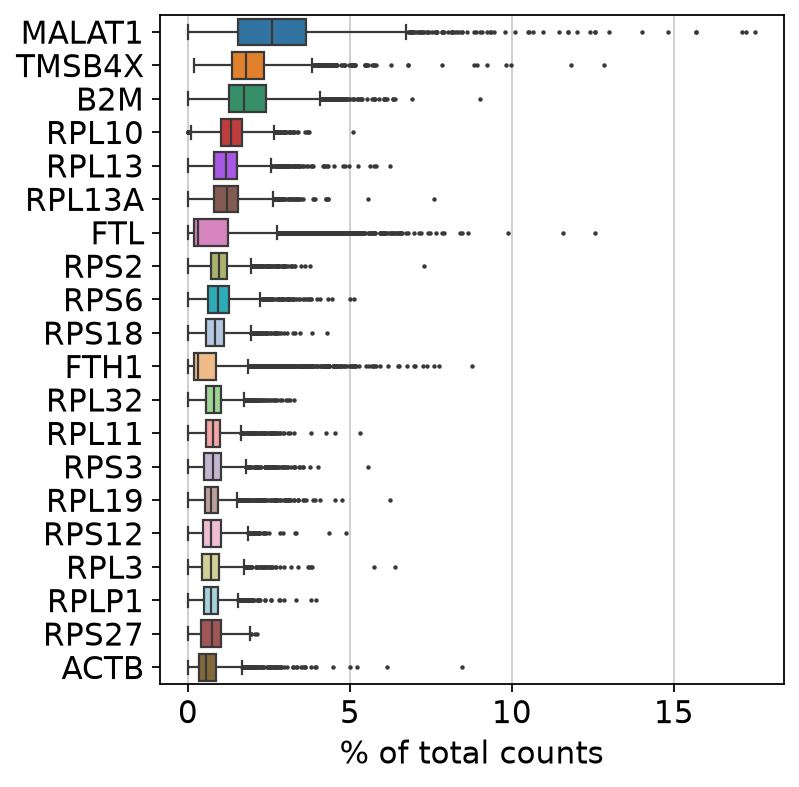

In [177]:
sc.pl.highest_expr_genes(adata, n_top=20)